In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve

In [2]:
alarmes = pd.read_csv('../../data/Alarmes/alarmes_trata_limpos_consolidado.csv')
zm01 = pd.read_excel('../../data/Corretiva Emergencial/processados/ZM01_limpa.xlsx', sheet_name='ZM01_limpa')
zm02 = pd.read_excel('../../data/Corretiva Programada/processados/ZM02_limpa.xlsx', sheet_name='ZM02_limpa')
zm03 = pd.read_csv('../../data/Preventiva/preventiva_zm03_limpa.csv')

print(alarmes.shape, zm01.shape, zm02.shape, zm03.shape)

# Une corretiva emergencial (zm01) e programada (zm02) num único dataframe de manutenções,
# para ter mais exemplos (principalmente da classe rara falha_proximos_7d = 0). As duas
# planilhas têm o mesmo esquema de colunas; `tipo_de_nota` (Z1 = emergencial, Z2 = programada)
# preserva a origem de cada linha. O restante do notebook usa `zm01` sem alterações.
zm01 = pd.concat([zm01, zm02], ignore_index=True, sort=False)
print(f"\nZM01 (emergencial) + ZM02 (programada) unidos: {zm01.shape}")
print(zm01['tipo_de_nota'].value_counts())

(742506, 15) (10543, 27) (1163, 27) (569, 19)

ZM01 (emergencial) + ZM02 (programada) unidos: (11706, 30)
tipo_de_nota
Z1    10543
Z2     1163
Name: count, dtype: int64


In [3]:
alarmes.head(5)

numeroAlarmesEstacao = alarmes['Estação'].value_counts()

## Pré Processamento

### Transformando em Datetime

In [4]:
zm01["T"] = pd.to_datetime(zm01["inicio_avaria_datetime"], errors="coerce")
zm01['fim_avaria_datetime'] = pd.to_datetime(zm01['fim_avaria_datetime'], errors='coerce')
alarmes['Horário do Alarme'] = pd.to_datetime(alarmes['Horário do Alarme'], errors='coerce')
alarmes['dt_alarme'] = pd.to_datetime(alarmes['dt_alarme'], errors='coerce')
alarmes['dt_normalizacao'] = pd.to_datetime(alarmes['dt_normalizacao'], errors='coerce')
alarmes.head(5)

,TAG,Horário do Alarme,Estação,Porta,Alarme,Horário da Normalizacao,Tempo de Normalização,tempo_normalizacao_seg,dt_alarme,dt_normalizacao,duracao_calculada_seg,estacao_extraida,plataforma_extraida,porta_extraida,tipo_evento_extraido
0,PSD_FAL_FAL2_PDM09_OBS,2026-05-12 08:16:52.657,FAL,9.0,OBS,2026-05-12 08:16:53.670,"0 dias, 00:00:01",1,2026-05-12 08:16:52.657,2026-05-12 08:16:53.670,1.013,FAL,FAL2,9.0,OBS
1,PSD_LUZ_LUZ1_PDM08_OBS,2026-05-12 08:15:09.913,LUZ,8.0,OBS,2026-05-12 08:15:10.917,"0 dias, 00:00:01",1,2026-05-12 08:15:09.913,2026-05-12 08:15:10.917,1.004,LUZ,LUZ1,8.0,OBS
2,PSD_FAL_FAL1_PDM15_OBS,2026-05-12 08:14:06.657,FAL,15.0,OBS,2026-05-12 08:14:07.670,"0 dias, 00:00:01",1,2026-05-12 08:14:06.657,2026-05-12 08:14:07.670,1.013,FAL,FAL1,15.0,OBS
3,PSD_LUZ_LUZ1_PDM19_OBS,2026-05-12 08:09:31.930,LUZ,19.0,OBS,2026-05-12 08:09:32.917,"0 dias, 00:00:01",1,2026-05-12 08:09:31.930,2026-05-12 08:09:32.917,0.987,LUZ,LUZ1,19.0,OBS
4,PSD_FRE_FRE1_PDM14_OBS,2026-05-12 08:05:05.830,FRE,14.0,OBS,2026-05-12 08:05:14.847,"0 dias, 00:00:09",9,2026-05-12 08:05:05.830,2026-05-12 08:05:14.847,9.017,FRE,FRE1,14.0,OBS


In [5]:
# 1. Calcula a duração em segundos (caso ainda não tenha essa coluna)
zm01['estacao'] = zm01['local_de_instalacao'].str.extract(r'PSD-([A-Z0-9]+)')
alarmes["duracao_segundos"] = (
    alarmes["dt_normalizacao"] - alarmes["dt_alarme"]
).dt.total_seconds()

# 2. Identifica os alarmes de OBS com menos de 30s
obs_curto = alarmes["Alarme"].astype(str).str.contains(
    "OBS", case=False, na=False
) & (alarmes["duracao_segundos"] < 30)

# 3. Mantém apenas os alarmes válidos na tabela
alarmes = alarmes[~obs_curto].reset_index(drop=True)

zm01.head(5)

,linha_origem,tipo_de_nota,nota,ordem,perfil_do_catalogo,descricao,local_de_instalacao,centro_de_trabalho_responsavel,inicio_avaria_datetime,fim_avaria_datetime,...,sintoma,objeto,defeito,causa,acao,nota_repetida_flag,duracao_extrema_flag,duracao_zero_flag,T,estacao
0,2,Z1,14943931,53954586.0,6PSD,PSD PL 01-02 Sem status para o CCO,SP04-6-PSD-BUT,SP04IBUT,2025-11-14 06:35:28,NaT,...,LAÇO DE PDM ABERTO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-11-14 06:35:28,BUT
1,3,Z1,15133619,54145839.0,6PSD,PSD - PDM's não abriram PLT02,SP04-6-PSD-BUT,SP04IBUT,2026-02-27 07:33:00,2026-02-27 12:00:00,...,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO,RESETADO E TESTADO,NaN,NaN,NaN,2026-02-27 07:33:00,BUT
2,4,Z1,13894133,52913343.0,6PSD,PSD server s/ status das plataformas,SP04-6-PSD-BUT-P1S1,SP04IBUT,2024-04-18 06:00:00,2024-04-18 07:30:00,...,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE,RESETADO E TESTADO,NaN,NaN,NaN,2024-04-18 06:00:00,BUT
3,5,Z1,14713349,53724958.0,6PSD,BUT PLT 1 PORTAS NAO ABRIRAM,SP04-6-PSD-BUT-P1S1,SP04IBUT,2025-07-07 18:38:00,2025-07-08 03:00:00,...,TODAS AS PDM DA FACHADA NÃO ABREM,CABO/CONECTORES,SWITCH TRAVADO,DESGASTE,RESETADO E TESTADO,NaN,NaN,NaN,2025-07-07 18:38:00,BUT
4,6,Z1,14643768,53655728.0,6PSD,PSD plt 1 - Falha geral de abertura,SP04-6-PSD-BUT-P1S1-PSSE1,SP04IBUT,2025-05-28 09:10:00,2025-05-28 10:00:00,...,PDM NÃO ABRE,CABEAMENTO,BAIXA ISOLACAO,FALHA CBTC,RESETADO E TESTADO,NaN,NaN,NaN,2025-05-28 09:10:00,BUT


In [6]:
# Ordena os DataFrames por estação e tempo
zm01 = zm01.sort_values(["estacao", "T"]).reset_index(drop=True)
alarmes = (
    alarmes.sort_values(["Estação", "dt_alarme"])
    .dropna(subset=["dt_alarme"])
    .reset_index(drop=True)
)

### Features

In [7]:
# Feature - Nome da estação
zm01['estacao'] = zm01['local_de_instalacao'].str.extract(r'PSD-([A-Z0-9]+)')

In [8]:
# Feature - Numero de Alarmes por Estação
zm01['numero_alarmes'] = zm01['estacao'].map(numeroAlarmesEstacao).fillna(0).astype(int)

In [9]:
# Feature - Alarmes Antes Manutencao

datas_alarmes_ordenadas = (
    alarmes["Horário do Alarme"].dropna().sort_values().values
)

total_alarmes = len(datas_alarmes_ordenadas)

zm01["alarmes_antes_manu"] = np.searchsorted(
    datas_alarmes_ordenadas, zm01["fim_avaria_datetime"].values, side="left"
)
zm01.loc[zm01["fim_avaria_datetime"].isna(), "alarmes_antes_manu"] = 0

In [10]:
# 1. Feature: dias_desde_ultima_manutencao
zm01["ultima_manu_fim"] = zm01.groupby("estacao")["fim_avaria_datetime"].shift(1)
zm01["dias_desde_ultima_manutencao"] = (zm01["T"] - zm01["ultima_manu_fim"]).dt.total_seconds() / 86400.0
zm01["dias_desde_ultima_manutencao"] = zm01["dias_desde_ultima_manutencao"].fillna(-1)

In [11]:
def calcular_janelas(df_zm, df_alt):
    cnt_24h = np.zeros(len(df_zm), dtype=int)
    cnt_7d = np.zeros(len(df_zm), dtype=int)

    for estacao, grp_zm in df_zm.groupby("estacao"):
        grp_alt = df_alt[df_alt["Estação"] == estacao]
        if grp_alt.empty:
            continue

        # Converte explicitamente para array nativo datetime64[ns] do NumPy (Evita o TypeError)
        times_alt = grp_alt["dt_alarme"].to_numpy(dtype="datetime64[ns]")
        times_zm = grp_zm["T"].to_numpy(dtype="datetime64[ns]")

        idx_t = np.searchsorted(times_alt, times_zm, side="right")
        idx_24h = np.searchsorted(
            times_alt, times_zm - np.timedelta64(24, "h"), side="left"
        )
        idx_7d = np.searchsorted(
            times_alt, times_zm - np.timedelta64(7, "D"), side="left"
        )

        cnt_24h[grp_zm.index] = idx_t - idx_24h
        cnt_7d[grp_zm.index] = idx_t - idx_7d

    return cnt_24h, cnt_7d

In [12]:
zm01["alarmes_ultimas_24h"], zm01["alarmes_ultimos_7d"] = calcular_janelas(zm01, alarmes)

media_diaria_7d = zm01["alarmes_ultimos_7d"] / 7.0
zm01["tendencia_alarmes"] = np.where(media_diaria_7d > 0, zm01["alarmes_ultimas_24h"] / media_diaria_7d, 0.0)

zm01['tendencia_alarmes'].value_counts()

tendencia_alarmes
0.000000    5706
7.000000      72
1.925784      24
0.176554      24
1.995098      23
            ... 
0.478632       1
0.663793       1
4.693798       1
4.569444       1
1.857516       1
Name: count, Length: 4835, dtype: int64

### Novas Features (guiadas pelo gráfico de importância e pelo mapa de correlação)

- `numero_manutencoes_anteriores`: quantas manutenções a estação já teve antes desta (histórico de reincidência).
- `duracao_media_manutencoes_anteriores`: duração média (em horas) das manutenções anteriores da estação — usa `shift(1)` para não vazar a duração da própria ocorrência atual.
- `dia_semana` e `mes`: sazonalidade da manutenção, extraídos de `T`.

In [13]:
# Feature - Número de manutenções anteriores na estação (conta só o passado, sem vazamento)
zm01["numero_manutencoes_anteriores"] = zm01.groupby("estacao").cumcount()

# Feature - Duração média das manutenções anteriores na estação
zm01["duracao_media_manutencoes_anteriores"] = zm01.groupby("estacao")["duracao_avaria_horas"].transform(
    lambda s: s.shift(1).expanding().mean()
)
zm01["duracao_media_manutencoes_anteriores"] = zm01["duracao_media_manutencoes_anteriores"].fillna(0)

# Feature - Sazonalidade
zm01["dia_semana"] = zm01["T"].dt.dayofweek
zm01["mes"] = zm01["T"].dt.month

## Transformações de Variáveis Categóricas

In [14]:
zm01.dtypes

linha_origem                                     int64
tipo_de_nota                                       str
nota                                             int64
ordem                                          float64
perfil_do_catalogo                                 str
descricao                                          str
local_de_instalacao                                str
centro_de_trabalho_responsavel                     str
inicio_avaria_datetime                  datetime64[us]
fim_avaria_datetime                     datetime64[us]
duracao_avaria_horas                           float64
analise_datetime                        datetime64[us]
encerramento_datetime                   datetime64[us]
indisponivel_flag                                 bool
falha_flag                                      object
analisada_flag                                    bool
ordem_ausente_flag                                bool
ordem_repetida_flag                               bool
comentario

### Label Encoder

In [15]:
colunas_categoricas = [
    "estacao",
    "defeito",
    "sintoma",
    "objeto",
]

label_encoders = {}

for col in colunas_categoricas:
    le = LabelEncoder()
    zm01[col] = le.fit_transform(zm01[col].astype(str))
    label_encoders[col] = le

zm01.head(5)

,linha_origem,tipo_de_nota,nota,ordem,perfil_do_catalogo,descricao,local_de_instalacao,centro_de_trabalho_responsavel,inicio_avaria_datetime,fim_avaria_datetime,...,alarmes_antes_manu,ultima_manu_fim,dias_desde_ultima_manutencao,alarmes_ultimas_24h,alarmes_ultimos_7d,tendencia_alarmes,numero_manutencoes_anteriores,duracao_media_manutencoes_anteriores,dia_semana,mes
0,33,Z2,13036981,52078709.0,6PSD,Led apagado,SP04-6-PSD-BUT-PLT2-PP18PDM,SP04IBUT,2023-01-03 03:55:59,2023-01-20 02:00:00,...,0,NaT,-1.000000,0,0,0.0,0,0.000000,1,1
1,683,Z1,13036932,52078677.0,6PSD,PDM 18 - Falha de fechamento,SP04-6-PSD-BUT-PLT2-PP18PDM,SP04IBUT,2023-01-03 04:18:00,2023-01-03 04:48:16,...,0,2023-01-20 02:00:00,-16.904167,0,0,0.0,1,406.066944,1,1
2,533,Z1,13038801,52080470.0,6PSD,PDM 07 Falha na abertura,SP04-6-PSD-BUT-PLT2-PP07PDM,SP04IBUT,2023-01-04 06:30:00,2023-01-04 07:00:00,...,0,2023-01-03 04:48:16,1.070648,0,0,0.0,2,203.285694,2,1
3,615,Z1,13045687,52086918.0,6PSD,PDM11 - Falha no fechamento,SP04-6-PSD-BUT-PLT2-PP11PDM,SP04IBUT,2023-01-08 10:25:00,2023-01-08 15:00:13,...,0,2023-01-04 07:00:00,4.142361,0,0,0.0,3,135.690463,6,1
4,115,Z1,13052087,52093262.0,6PSD,PDM 09 - Falha de fechamento,SP04-6-PSD-BUT-PLT1-PP09PDM,SP04IBUT,2023-01-11 18:18:00,2023-01-12 04:47:05,...,0,2023-01-08 15:00:13,3.137350,0,0,0.0,4,102.914583,2,1


## Separando Dados de Teste e Treino

In [16]:
zm01 = zm01.sort_values(["estacao", "T"]).reset_index(drop=True)

zm01["proxima_avaria_datetime"] = zm01.groupby("estacao")["T"].shift(-1)

zm01["dias_ate_proxima_falha"] = (
    zm01["proxima_avaria_datetime"] - zm01["T"]
).dt.total_seconds() / 86400.0

zm01["falha_proximos_7d"] = (zm01["dias_ate_proxima_falha"] <= 7.0).astype(int)

df_modelo = zm01.dropna(subset=["dias_ate_proxima_falha"]).copy()

print(df_modelo["falha_proximos_7d"].value_counts())

falha_proximos_7d
1    11504
0      190
Name: count, dtype: int64


In [17]:
# Removidas: perfil_do_catalogo (constante, importância 0), centro_de_trabalho_responsavel
# (corr. 0.99 com estacao, redundante), analisada_flag/ordem_ausente_flag/ordem_repetida_flag
# (importância 0 no modelo treinado).
colunas_features = [
    "dias_desde_ultima_manutencao",
    "alarmes_ultimas_24h",
    "alarmes_ultimos_7d",
    "tendencia_alarmes",
    "estacao",
    "sintoma",
    "objeto",
    "defeito",
    "indisponivel_flag",
    "numero_manutencoes_anteriores",
    "duracao_media_manutencoes_anteriores",
    "dia_semana",
    "mes",
]

coluna_target = "falha_proximos_7d"

In [18]:
df_modelo = df_modelo.sort_values("T").reset_index(drop=True)

ponto_corte = df_modelo["T"].quantile(0.80)

treino_df = df_modelo[df_modelo["T"] < ponto_corte]
teste_df = df_modelo[df_modelo["T"] >= ponto_corte]

X_train = treino_df[colunas_features]
y_train = treino_df[coluna_target]

X_test = teste_df[colunas_features]
y_test = teste_df[coluna_target]

In [ ]:
# 1. Calculando a proporção real de desbalanceamento no treino
qtd_0 = (y_train == 0).sum()
qtd_1 = (y_train == 1).sum()
peso_desbalanceamento = (
    qtd_0 / qtd_1
)  # Como a classe 0 é a minoria, ajustamos o peso

# 2. Configura a grade. Inclui scale_pos_weight=1 (sem reponderação) para o
# search poder comparar de verdade se vale a pena forçar o balanceamento.
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "scale_pos_weight": [1, peso_desbalanceamento, peso_desbalanceamento * 2],
}

xgb = XGBClassifier(random_state=42, eval_metric="logloss")

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)

# 3. Avaliação
melhor_xgb = search.best_estimator_
y_pred = melhor_xgb.predict(X_test)

baseline_majoritaria = max(y_test.mean(), 1 - y_test.mean())

print(f"Baseline (sempre prever a classe majoritária): {baseline_majoritaria:.2%}")
print(f"Acurácia:            {accuracy_score(y_test, y_pred):.2%}")
print(f"Acurácia balanceada: {balanced_accuracy_score(y_test, y_pred):.2%}  <- métrica geral correta aqui")
print(f"Precisão (weighted): {precision_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print(f"Recall   (weighted): {recall_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print(f"F1       (weighted): {f1_score(y_test, y_pred, average='weighted', zero_division=0):.2%}")
print()
print(classification_report(y_test, y_pred, zero_division=0))

Baseline (sempre prever a classe majoritária): 98.85%
Acurácia:            90.47%
Acurácia balanceada: 60.40%  <- métrica geral correta aqui
Precisão (weighted): 98.01%
Recall   (weighted): 90.47%
F1       (weighted): 93.96%

              precision    recall  f1-score   support

           0       0.04      0.30      0.07        27
           1       0.99      0.91      0.95      2312

    accuracy                           0.90      2339
   macro avg       0.51      0.60      0.51      2339
weighted avg       0.98      0.90      0.94      2339



## Diagnóstico: overfitting vs. desbalanceamento

In [20]:
y_pred_train = melhor_xgb.predict(X_train)


def imprime_metricas_gerais(y_true, y_pred, titulo):
    baseline = max(y_true.mean(), 1 - y_true.mean())
    print(f"=== {titulo} ===")
    print(f"Baseline (classe majoritária): {baseline:.2%}")
    print(f"Acurácia:            {accuracy_score(y_true, y_pred):.2%}")
    print(f"Acurácia balanceada: {balanced_accuracy_score(y_true, y_pred):.2%}")
    print(f"Precisão (weighted): {precision_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"Recall   (weighted): {recall_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"F1       (weighted): {f1_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(classification_report(y_true, y_pred, zero_division=0))


imprime_metricas_gerais(y_train, y_pred_train, "TREINO")
imprime_metricas_gerais(y_test, y_pred, "TESTE")

# Desempenho parecido entre treino e teste => o modelo generaliza (não é overfitting).
# Treino muito melhor que teste => overfitting de verdade.
# Acurácia abaixo do baseline => o balanceamento forçado está custando mais do que ajudando.

=== TREINO ===
Baseline (classe majoritária): 98.26%
Acurácia:            79.33%
Acurácia balanceada: 77.73%
Precisão (weighted): 97.84%
Recall   (weighted): 79.33%
F1       (weighted): 86.96%
              precision    recall  f1-score   support

           0       0.06      0.76      0.11       163
           1       0.99      0.79      0.88      9192

    accuracy                           0.79      9355
   macro avg       0.53      0.78      0.50      9355
weighted avg       0.98      0.79      0.87      9355

=== TESTE ===
Baseline (classe majoritária): 98.85%
Acurácia:            90.47%
Acurácia balanceada: 60.40%
Precisão (weighted): 98.01%
Recall   (weighted): 90.47%
F1       (weighted): 93.96%
              precision    recall  f1-score   support

           0       0.04      0.30      0.07        27
           1       0.99      0.91      0.95      2312

    accuracy                           0.90      2339
   macro avg       0.51      0.60      0.51      2339
weighted avg    

In [21]:
# Verifica se falhas "muito próximas" (minutos/horas) estão inflando o dataset,
# o que indicaria reabertura/duplicata de chamado em vez de uma nova falha real.
for limite in [1 / 24, 1, 2]:  # 1h, 1 dia, 2 dias
    frac = (df_modelo["dias_ate_proxima_falha"] < limite).mean()
    print(f"% de falhas com a próxima ocorrendo em menos de {limite:.4f} dia(s): {frac:.1%}")

print()
print(pd.crosstab(df_modelo["dias_ate_proxima_falha"] < 1, df_modelo["ordem_repetida_flag"], normalize="index"))

% de falhas com a próxima ocorrendo em menos de 0.0417 dia(s): 17.7%
% de falhas com a próxima ocorrendo em menos de 1.0000 dia(s): 66.2%
% de falhas com a próxima ocorrendo em menos de 2.0000 dia(s): 82.2%

ordem_repetida_flag        False     True 
dias_ate_proxima_falha                    
False                   0.992919  0.007081
True                    0.984755  0.015245


## Importância das Features

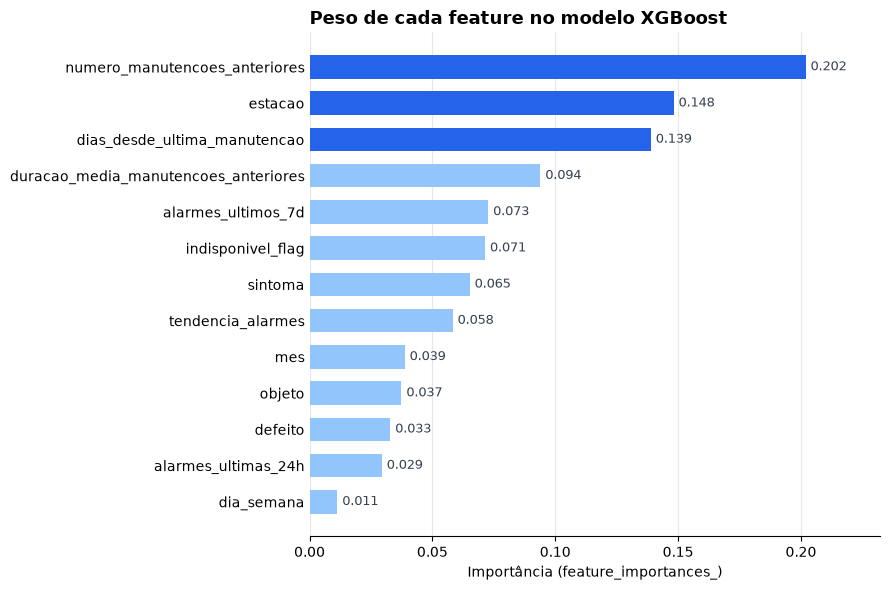

In [22]:
importancias = pd.Series(melhor_xgb.feature_importances_, index=colunas_features)
importancias = importancias.sort_values(ascending=True)

cor_base = "#93c5fd"
cor_destaque = "#2563eb"
n_destaque = 3
cores = [cor_destaque if i >= len(importancias) - n_destaque else cor_base for i in range(len(importancias))]

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(importancias.index, importancias.values, color=cores, height=0.65)

for barra, valor in zip(barras, importancias.values):
    ax.text(valor + importancias.max() * 0.01, barra.get_y() + barra.get_height() / 2,
             f"{valor:.3f}", va="center", ha="left", fontsize=9, color="#374151")

ax.set_xlabel("Importância (feature_importances_)")
ax.set_title("Peso de cada feature no modelo XGBoost", fontsize=13, fontweight="bold", loc="left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, importancias.max() * 1.15)
ax.grid(axis="x", color="#e5e7eb", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Mapa de Correlação

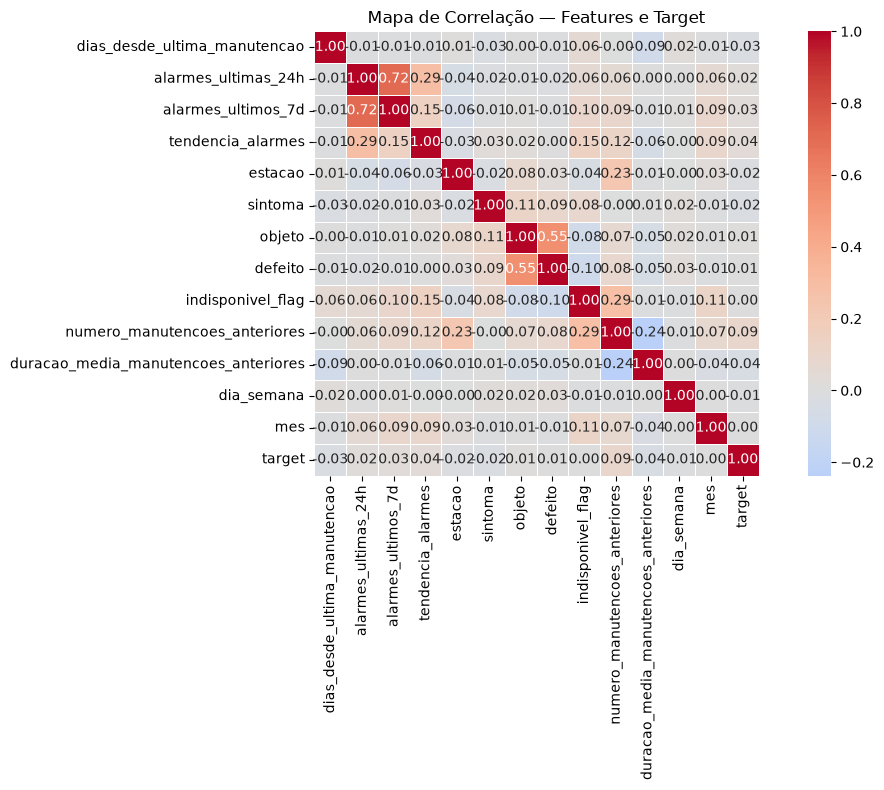

In [23]:
features = df_modelo[colunas_features]
corr_matrix = features.assign(target=df_modelo[coluna_target]).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True)
plt.title("Mapa de Correlação — Features e Target")
plt.tight_layout()
plt.show()